head:
   order_id customer_id product_id     category   price  discount  quantity  \
0  O100000      C17270    P234890         Home  164.08      0.15         1   
1  O100001      C17603    P228204      Grocery   24.73      0.00         1   
2  O100002      C10860    P213892  Electronics  175.58      0.05         1   
3  O100003      C15390    P208689  Electronics   63.67      0.00         1   
4  O100004      C15226    P228063         Home   16.33      0.15         1   

  payment_method  order_date  delivery_time_days region returned  \
0    Credit Card  2023-12-23                   4   West       No   
1    Credit Card  2025-04-03                   6  South       No   
2    Credit Card  2024-10-08                   4  North       No   
3            UPI  2024-09-14                   6  South       No   
4            COD  2024-12-21                   6   East       No   

   total_amount  shipping_cost  profit_margin  customer_age customer_gender  
0        139.47           7.88       

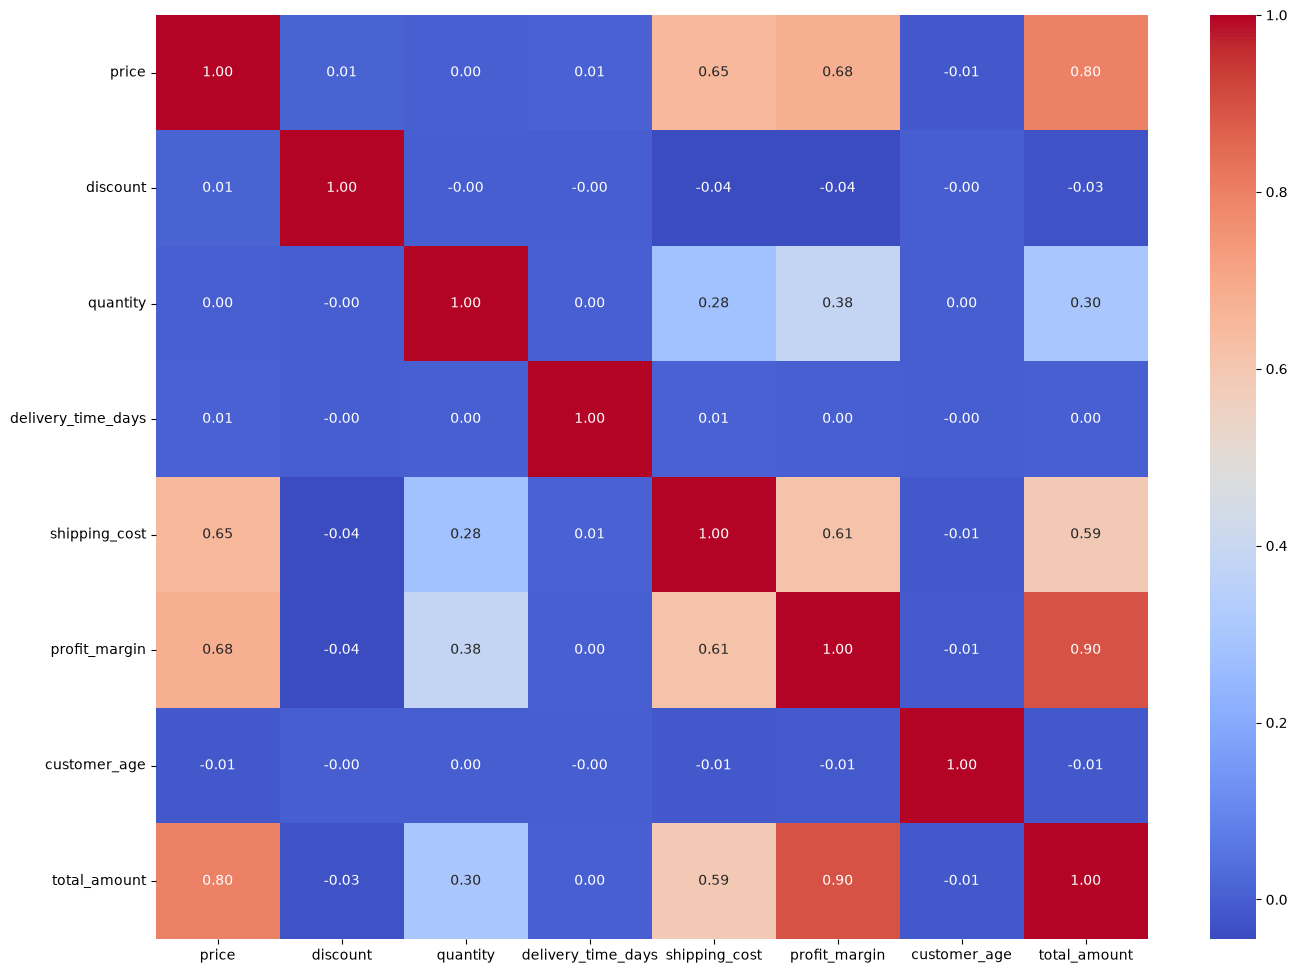

total_amount          1.000000
profit_margin         0.895507
price                 0.796614
shipping_cost         0.589157
quantity              0.299026
delivery_time_days    0.002694
customer_age         -0.014866
discount             -0.027636
Name: total_amount, dtype: float64

dtypes:
 price                 float64
discount              float64
quantity                int64
delivery_time_days      int64
total_amount          float64
shipping_cost         float64
profit_margin         float64
customer_age            int64
dtype: object
Розмірність датасету: (34500, 8)

y: total_amount
X: ['price', 'discount', 'quantity', 'delivery_time_days', 'shipping_cost', 'profit_margin', 'customer_age']
n = 34500, p = 7
n_train = 24150, n_test = 10350

Total amount = 12.2153 + 0.8110·price - 45.6856·discount + 32.6855·quantity - 0.5881·delivery_time_days - 16.1681·shipping_cost + 4.2483·profit_margin - 0.0654·customer_age

R            = 0.9356960943825667
R (adjusted) = 0.9356768085237599
R^

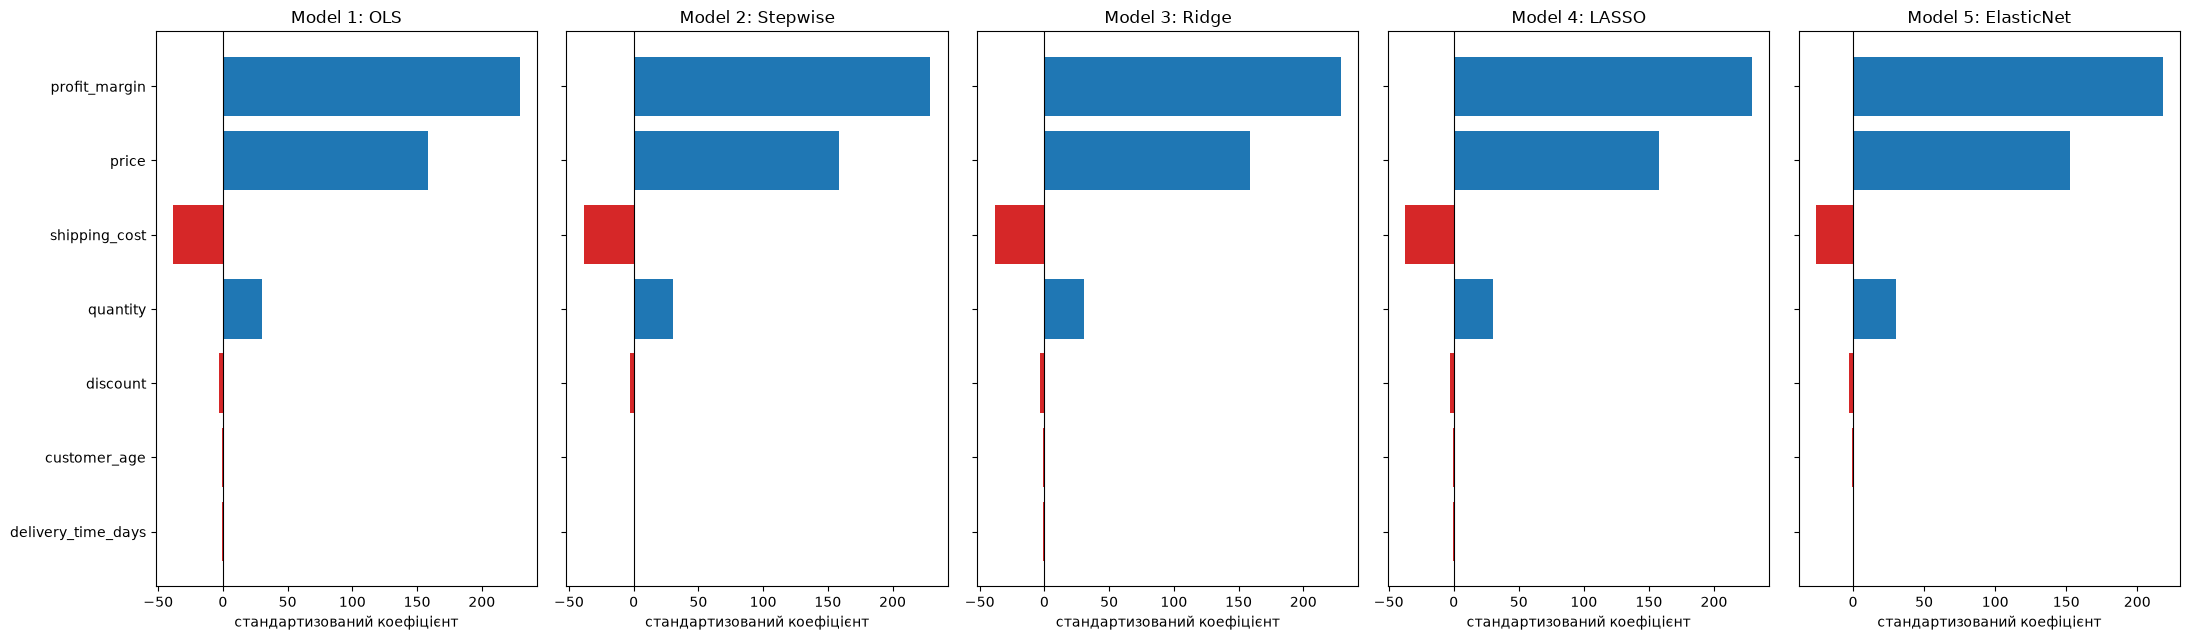


Важливість ознак (стандартизовані коефіцієнти):
                    Model 1: OLS  Model 2: Stepwise  Model 3: Ridge  \
profit_margin           229.2633           229.2713        229.2585   
price                   158.6638           158.6636        158.6605   
shipping_cost           -38.5156           -38.5101        -38.5148   
quantity                 30.5542            30.5487         30.5536   
discount                 -3.1975            -3.1952         -3.1974   
customer_age             -0.9815             0.0000         -0.9815   
delivery_time_days       -0.7281             0.0000         -0.7281   

                    Model 4: LASSO  Model 5: ElasticNet  
profit_margin             229.1740             217.8790  
price                     157.5246             152.4115  
shipping_cost             -37.1989             -26.0437  
quantity                   29.8934              30.0652  
discount                   -2.8046              -2.6607  
customer_age               -0.6536

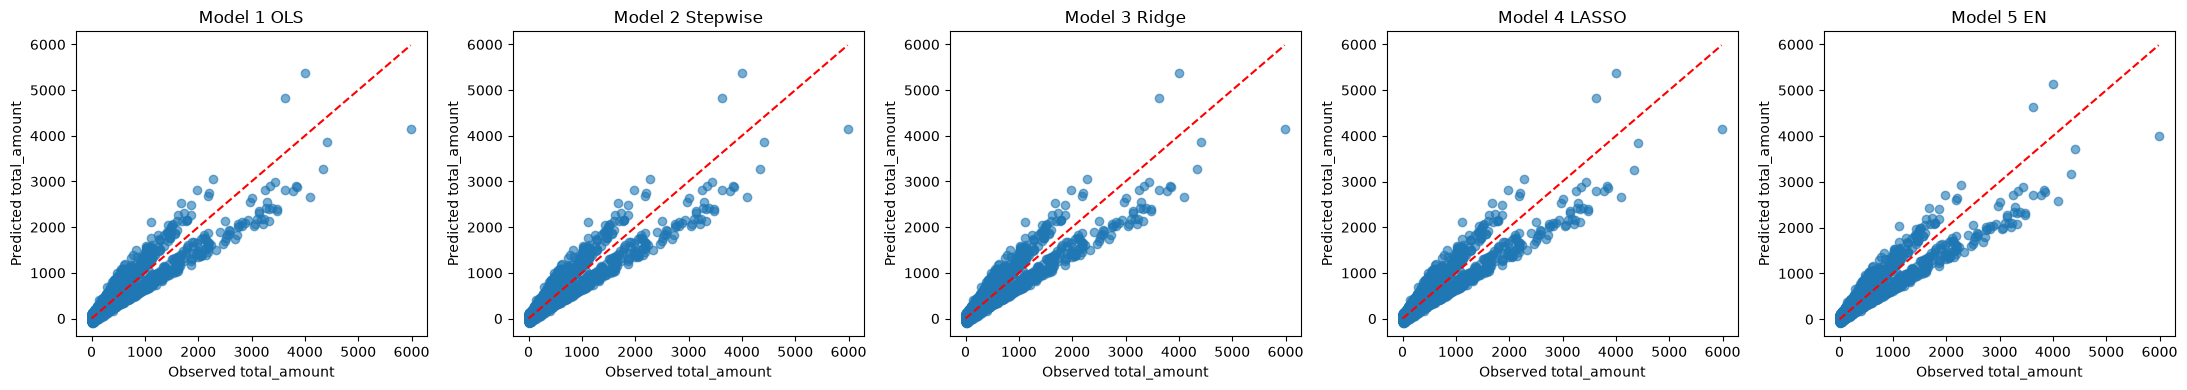

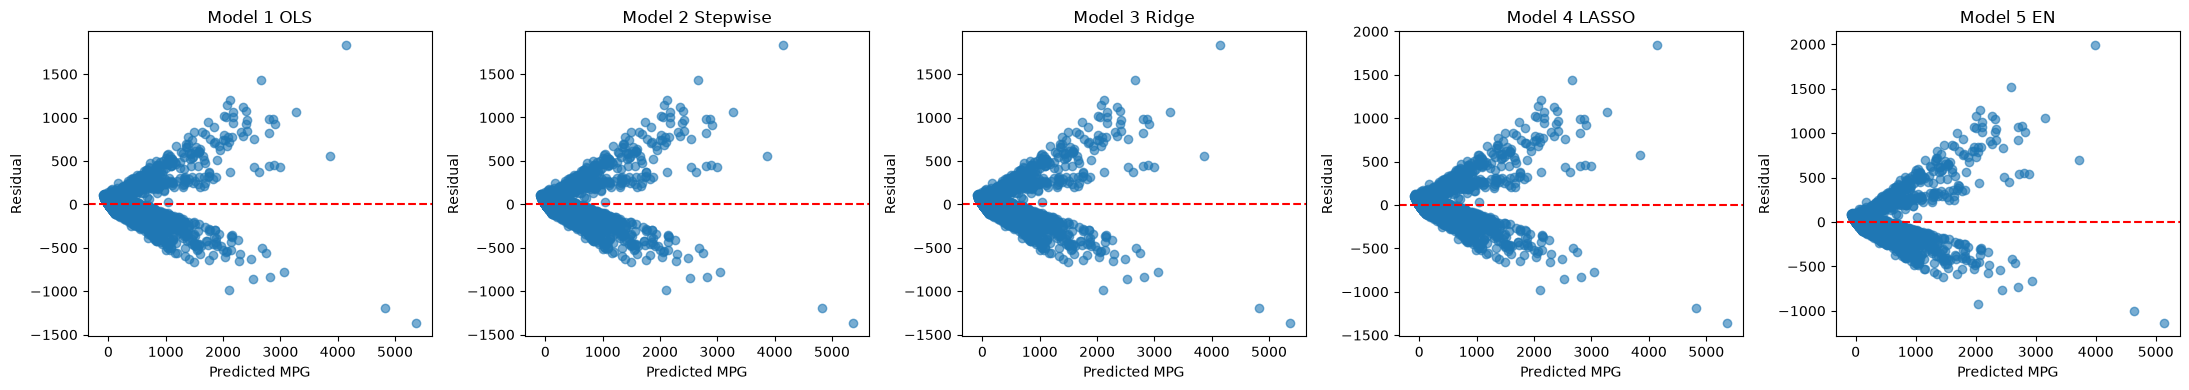


Порівняльна таблиця метрик:
              model sample        MSE     RMSE     MAE     R2
       Model 1: OLS  train 16445.3826 128.2396 63.8887 0.8755
       Model 1: OLS   test 14233.2707 119.3033 63.8414 0.8791
  Model 2: Stepwise  train 16446.8732 128.2454 63.8815 0.8755
  Model 2: Stepwise   test 14230.0027 119.2896 63.8183 0.8791
     Model 3: Ridge  train 16445.3826 128.2396 63.8887 0.8755
     Model 3: Ridge   test 14233.2703 119.3033 63.8413 0.8791
     Model 4: LASSO  train 16446.7697 128.2450 63.6214 0.8755
     Model 4: LASSO   test 14219.4118 119.2452 63.5755 0.8792
Model 5: ElasticNet  train 16592.1444 128.8105 61.3955 0.8744
Model 5: ElasticNet   test 14037.8750 118.4815 61.4914 0.8808

Найкраща модель за RMSE на тесті: Model 5: ElasticNet


In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

TARGET = "total_amount"
RANDOM_STATE = 42

def log_wrap(reg):
    return TransformedTargetRegressor(regressor=reg, func=np.log, inverse_func=np.exp)
def equation(intercept, coefs, names):
    s = f"Total amount = {intercept:.4f}"
    for c, name in zip(coefs, names):
        s += f" {'+' if c >= 0 else '-'} {abs(c):.4f}·{name}"
    return s


def evaluate(name, model, X_te, y_te):
    pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    mae = mean_absolute_error(y_te, pred)
    print(f"{name:14s} R2={r2_score(y_te, pred):.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}")

df = pd.read_csv("ecommerce_sales_34500.csv")
print("head:\n", df.head())
print("\ninfo:")
df.info()
print("\ndescribe:\n", df.describe())

print("\nКількість пропусків у кожному стовпці:")
print(df.isnull().sum())

df = df.drop_duplicates()

df = df.select_dtypes(include=["number", "bool"]).copy()

id_like = [
    c for c in df.columns
    if c != TARGET and (
        c.lower().endswith("id") or c.lower() in ("id", "index")
    )
]
to_drop = sorted(set(id_like) & set(df.columns))
if to_drop:
    print("\nВидаляємо стовпці:", to_drop)
    df = df.drop(columns=to_drop)
df = df.dropna()

n = df.shape[0]
p = df.shape[1] - 1
print(f"\nОчищення завершено. n = {n}, p = {p}")

y = df[TARGET]
X = df.drop(columns=[TARGET]).astype(float)
factors = X.columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

train_df = X_train.copy()
train_df[TARGET] = y_train

corr = train_df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

print(corr[TARGET].sort_values(ascending=False))

print("\ndtypes:\n", df.dtypes)
print("Розмірність датасету:", df.shape)



print("\ny:", TARGET)
print("X:", factors)
print(f"n = {X.shape[0]}, p = {X.shape[1]}")

print(f"n_train = {len(X_train)}, n_test = {len(X_test)}")

model1 = LinearRegression().fit(X_train, y_train)
ols1 = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print("\n" + equation(model1.intercept_, model1.coef_, factors))
print("\nR            =", np.sqrt(ols1.rsquared)) 
print("R (adjusted) =", np.sqrt(ols1.rsquared_adj))
print("R^2          =", ols1.rsquared)
print("R^2 adjusted =", ols1.rsquared_adj) 
print("F            =", ols1.fvalue)
print("p-value (F)  =", ols1.f_pvalue) 

coef_table = pd.DataFrame({"coef": ols1.params,"t": ols1.tvalues,"p-value": ols1.pvalues,"significant": ols1.pvalues < 0.05,})
print("\n", coef_table)
# print(ols1.summary())

x_vif = sm.add_constant(X_train[factors])
vif = pd.DataFrame({
    "Factor": factors,
    "VIF": [variance_inflation_factor(x_vif.values, i + 1) for i in range(len(factors))]
})

print("\nVIF (значення > 5-10 означають сильну мультиколінеарність):")
print(vif.sort_values(by="VIF", ascending=False))

selected = factors.copy()
ols_step = None
while selected:
    ols_step = sm.OLS(y_train, sm.add_constant(X_train[selected])).fit()
    pvals = ols_step.pvalues.drop("const")
    if pvals.max() < 0.05:
        break
    worst = pvals.idxmax()
    print(f"Видалено {worst} (p = {pvals.max():.4f})")
    selected.remove(worst)


print("Відібрані змінні:", selected)
model2 = LinearRegression().fit(X_train[selected], y_train)
print(equation(model2.intercept_, model2.coef_, selected))
# print(ols_step.summary())

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


def to_original(model):
    coefs = model.coef_ / scaler.scale_
    intercept = model.intercept_ - np.sum(coefs * scaler.mean_)
    return intercept, coefs


model3 = RidgeCV(alphas=np.logspace(-3, 3, 100)).fit(X_train_s, y_train)
print("\nRidge alpha =", model3.alpha_)
print(equation(*to_original(model3), factors))

model4 = LassoCV(cv=5, random_state=RANDOM_STATE).fit(X_train_s, y_train)
print("\nLasso alpha =", model4.alpha_)
print(equation(*to_original(model4), factors))
print("Обнулені змінні:", [f for f, c in zip(factors, model4.coef_) if np.isclose(c, 0)])

model5 = ElasticNetCV(
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=5, random_state=RANDOM_STATE
).fit(X_train_s, y_train)
print("\nElasticNet alpha    =", model5.alpha_)
print("ElasticNet l1_ratio =", model5.l1_ratio_)
print(equation(*to_original(model5), factors))

print("\nОцінка на тестовій вибірці:")
evaluate("OLS full", model1, X_test, y_test)
evaluate("OLS stepwise", model2, X_test[selected], y_test)
evaluate("Ridge", model3, X_test_s, y_test)
evaluate("Lasso", model4, X_test_s, y_test)
evaluate("ElasticNet", model5, X_test_s, y_test)

models = {
    "Model 1: OLS":        (model1, X_train,             X_test),
    "Model 2: Stepwise":   (model2, X_train[selected],   X_test[selected]),
    "Model 3: Ridge":      (model3, X_train_s,           X_test_s),
    "Model 4: LASSO":      (model4, X_train_s,           X_test_s),
    "Model 5: ElasticNet": (model5, X_train_s,           X_test_s),
}


sd = X_train.std()
imp = pd.DataFrame(index=factors)
imp["Model 1: OLS"] = pd.Series(model1.coef_, index=factors) * sd
imp["Model 2: Stepwise"] = (pd.Series(model2.coef_, index=selected) * sd[selected]).reindex(factors).fillna(0)
imp["Model 3: Ridge"] = model3.coef_
imp["Model 4: LASSO"] = model4.coef_
imp["Model 5: ElasticNet"] = model5.coef_

order = imp["Model 1: OLS"].abs().sort_values(ascending=True).index
imp = imp.loc[order]

fig, axes = plt.subplots(1, 5, figsize=(22, 0.5 * len(factors) + 3), sharey=True)
for ax, col in zip(axes, imp.columns):
    ax.barh(imp.index, imp[col], color=np.where(imp[col] >= 0, "tab:blue", "tab:red"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(col)
    ax.set_xlabel("стандартизований коефіцієнт")
plt.tight_layout()
plt.show()

print("\nВажливість ознак (стандартизовані коефіцієнти):")
print(imp.sort_values("Model 1: OLS", key=abs, ascending=False).round(4))

pred_train = {
    "Model 1 OLS": model1.predict(X_train),
    "Model 2 Stepwise": model2.predict(X_train[selected]),
    "Model 3 Ridge": model3.predict(X_train_s),
    "Model 4 LASSO": model4.predict(X_train_s),
    "Model 5 EN": model5.predict(X_train_s),
}
pred_test = {
    "Model 1 OLS": model1.predict(X_test),
    "Model 2 Stepwise": model2.predict(X_test[selected]),
    "Model 3 Ridge": model3.predict(X_test_s),
    "Model 4 LASSO": model4.predict(X_test_s),
    "Model 5 EN": model5.predict(X_test_s),
}
pred_table = pd.DataFrame(pred_test, index=y_test.index)
pred_table.insert(0, "Observed", y_test)
print(pred_table.head(7).round(2))
# n_show = 6
# for name, (m, Xtr, Xte) in models.items():
#     pred_te = m.predict(Xte)
#     table = pd.DataFrame({
#         "observed": y_test.values[:n_show],
#         "predicted": pred_te[:n_show],
#     })
#     table["error"] = table["observed"] - table["predicted"]
#     print(f"\n{name}: прогноз на тесті (перші {n_show})")
#     print(table.round(3))
# for name, (m, Xtr, Xte) in models.items():
#     t = pd.DataFrame({"observed": y_train.values[:n_show],"predicted": m.predict(Xtr)[:n_show]})
#     t["error"] = t["observed"] - t["predicted"]
#     print(f"\n{name}: прогноз на train (перші {n_show})")
#     print(t.round(3))
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pred) in zip(axes, pred_test.items()):
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    ax.set_title(name)
    ax.set_xlabel("Observed total_amount")
    ax.set_ylabel("Predicted total_amount")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pred) in zip(axes, pred_test.items()):
    ax.scatter(pred, y_test - pred, alpha=0.6)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted MPG")
    ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()
rows = []
for name, (m, Xtr, Xte) in models.items():
    for part, Xp, yp in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        pred = m.predict(Xp)
        mse = mean_squared_error(yp, pred)
        rows.append({
            "model": name, "sample": part,
            "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(yp, pred),
            "R2": r2_score(yp, pred),
        })
metrics = pd.DataFrame(rows)
print("\nПорівняльна таблиця метрик:")
print(metrics.round(4).to_string(index=False))

test_m = metrics[metrics["sample"] == "test"].set_index("model")
best = test_m["RMSE"].idxmin()
print(f"\nНайкраща модель за RMSE на тесті: {best}")